# Case 3: The peek

**Applies chapter 3:** train, validation, test, and why the test slice is spent once. It starts from case 2's state: the same split and the same logistic model, scoring 0.8971 against the baseline's 0.8874.

A junior on the bank's team is short of time. Instead of choosing a model on validation and scoring the test once, they try 60 versions of the model, each with a different list of columns, score every version on the held-out slice, and keep the best. The best number goes in the status update. This notebook stages that peek and catches it.

The real test slice stays sealed in its envelope. A practice envelope of 2,000 validation rows plays its part, and the other 6,238 validation rows are the fresh slice nobody looked at.

By the end of this notebook you can:

- show how choosing by a held-out score inflates that score;
- measure the inflation against a fresh slice;
- say in one sentence why the test slice is spent once.

**Search terms:** test set leakage, selection bias in model evaluation, data snooping, holdout set.

In [1]:
# Tools for this notebook, and one helper that prints a check as PASS or FAIL.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def check(label, ok):
    print(("PASS  " if ok else "FAIL  ") + label)

In [2]:
# Load the day's public dataset once; later runs read the cached copy.
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

bank = load_bank()
print(bank.shape)

(41188, 21)


In [3]:
# The week's pipeline: the same columns, the same split and the same model every day.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# The customer table on the morning of the call: who the client is and how earlier campaigns went.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
COLUMNS = PROFILE + HISTORY

def week_split(df, seed=42):
    """Test is sealed first (20 percent, the envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

def logistic(columns, df):
    # pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

train, val, test = week_split(bank, seed=42)
y = (bank["y"] == "yes").astype(int)
# Carve the practice envelope out of validation; the real test slice is never used here.
peek_idx, fresh_idx = train_test_split(val.index, train_size=2000, stratify=y.loc[val.index], random_state=7)
print(f"practice envelope {len(peek_idx):,} rows, fresh slice {len(fresh_idx):,} rows, real test {len(test):,} rows sealed")
check("the practice envelope and the fresh slice share no row", len(set(peek_idx) & set(fresh_idx)) == 0)
check("neither touches the sealed test slice", len((set(peek_idx) | set(fresh_idx)) & set(test.index)) == 0)

practice envelope 2,000 rows, fresh slice 6,238 rows, real test 8,238 rows sealed
PASS  the practice envelope and the fresh slice share no row
PASS  neither touches the sealed test slice


## What does the junior's loop report?

Sixty versions, each a random list of 3 to 13 of today's columns, each fitted on train and scored on the practice envelope. The loop keeps whichever scored highest there.

**Predict before you run.** The best of the 60 on the practice envelope will sit how far above doing nothing on that slice? (a) below it (b) about one point (c) close to two points (d) ten points

In [4]:
# The junior's loop: 60 column lists, each scored on the practice envelope; keep the best.
rng = np.random.default_rng(42)
rows = []
for k in range(60):
    cols = [str(c) for c in rng.choice(COLUMNS, size=int(rng.integers(3, 14)), replace=False)]
    m = logistic(cols, bank).fit(train[cols], y.loc[train.index])
    rows.append({"version": k, "n_cols": len(cols), "cols": cols,
                 "peek": accuracy_score(y.loc[peek_idx], m.predict(bank.loc[peek_idx, cols])),
                 "fresh": accuracy_score(y.loc[fresh_idx], m.predict(bank.loc[fresh_idx, cols]))})
runs = pd.DataFrame(rows)
best = runs.loc[runs["peek"].idxmax()]
base_peek = 1 - y.loc[peek_idx].mean()
base_fresh = 1 - y.loc[fresh_idx].mean()
print(f"doing nothing on the practice envelope: {base_peek:.4f}")
print(f"best of 60 on the practice envelope:    {best['peek']:.4f}  (version {best['version']}, {best['n_cols']} columns)")
print(f"edge as reported: {100 * (best['peek'] - base_peek):.2f} points")

doing nothing on the practice envelope: 0.8875
best of 60 on the practice envelope:    0.9055  (version 45, 7 columns)
edge as reported: 1.80 points


**What happened.** The answer is (c): the chosen version reads 0.9055 on the practice envelope, 1.8 points above doing nothing there. That is nearly double the edge case 2 measured honestly. Now score the same chosen version on rows nobody looked at.

**Predict before you run.** On the fresh 6,238 rows, the chosen version scores (a) about 0.906 again (b) about 0.897 (c) about 0.887 (d) about 0.80

In [5]:
# Score the chosen version on the fresh slice, which played no part in the choice.
print(f"doing nothing on the fresh slice:   {base_fresh:.4f}")
print(f"the chosen version on the fresh slice: {best['fresh']:.4f}")
print(f"edge on fresh rows: {100 * (best['fresh'] - base_fresh):.2f} points, against {100 * (best['peek'] - base_peek):.2f} reported")
check("the reported score falls on fresh rows", best["fresh"] < best["peek"])
check("the chosen version is the maximum of the peeked scores", best["peek"] == runs["peek"].max())

doing nothing on the fresh slice:   0.8873
the chosen version on the fresh slice: 0.8971
edge on fresh rows: 0.98 points, against 1.80 reported
PASS  the reported score falls on fresh rows
PASS  the chosen version is the maximum of the peeked scores


**What happened.** The answer is (b): 0.8971 on fresh rows, one point above doing nothing, which is exactly the honest edge from case 2. The extra 0.8 points were luck: among 60 versions scored on the same 2,000 rows, one was bound to be lucky on those rows, and the loop picked the luckiest.

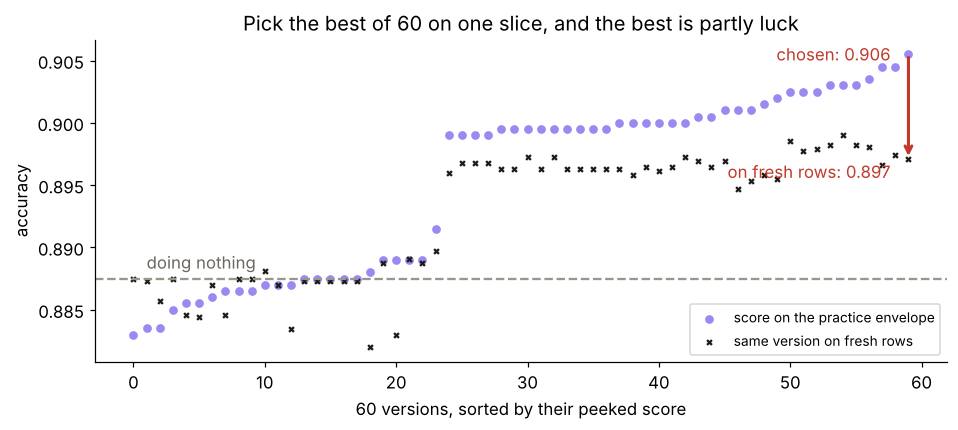

In [6]:
# Picture the peek: every version's peeked score, the chosen one, and where it lands on fresh rows.
fig, ax = plt.subplots(figsize=(10, 3.8))
order = runs.sort_values("peek").reset_index(drop=True)
ax.scatter(range(len(order)), order["peek"], color="#9C88F0", s=22, label="score on the practice envelope")
ax.scatter(range(len(order)), order["fresh"], color="#1C1B16", s=10, marker="x", label="same version on fresh rows")
ax.axhline(base_peek, color="#9A968C", ls="--"); ax.text(1, base_peek + 0.0008, "doing nothing", color="#6B675E")
i = len(order) - 1
ax.annotate("", xy=(i, order.loc[i, "fresh"]), xytext=(i, order.loc[i, "peek"]),
            arrowprops=dict(arrowstyle="->", color="#C0392B", lw=2))
ax.text(i - 1, order.loc[i, "peek"], "chosen: 0.906 ", ha="right", va="center", color="#C0392B")
ax.text(i - 1, order.loc[i, "fresh"] - 0.0015, "on fresh rows: 0.897 ", ha="right", color="#C0392B")
ax.set_xlabel("60 versions, sorted by their peeked score"); ax.set_ylabel("accuracy")
ax.legend(loc="lower right", fontsize=9); ax.set_title("Pick the best of 60 on one slice, and the best is partly luck")
plt.show()

## Why does the peek inflate, and what is the rule?

The peeked scores spread out by chance alone, because 2,000 rows is a small sample. Their spread, next to their spread on the bigger fresh slice, shows how much luck a single slice carries.

In [7]:
# How noisy is one slice? Compare the spread of the 60 scores on each slice.
spread_peek = runs["peek"].std()
spread_fresh = runs["fresh"].std()
print(f"spread of the 60 scores on the practice envelope: {spread_peek:.4f}")
print(f"spread of the 60 scores on the fresh slice:       {spread_fresh:.4f}")
print(f"the best peeked score sits {(best['peek'] - runs['peek'].mean()) / spread_peek:.1f} spreads above the average version")
check("the small slice is the noisier one", spread_peek > spread_fresh)

spread of the 60 scores on the practice envelope: 0.0072
spread of the 60 scores on the fresh slice:       0.0052
the best peeked score sits 1.4 spreads above the average version
PASS  the small slice is the noisier one


**The rule.** Choose on validation, as often as you like. Score the test slice once, at the end, and report that one number with its seed. A test score used to choose anything becomes a second validation score, optimistic by however much the choosing bought.

**The envelope.** The trainer's card on the wall reads TEST SET, DO NOT OPEN UNTIL FRIDAY. Every request to peek this week points at it. On Friday it is opened once, the chosen model is scored once, and that number goes in the memo.

## What did this notebook establish?

| Question | Answer |
|---|---|
| What did the peek report? | 0.9055 on the practice envelope, 1.8 points above doing nothing |
| What did fresh rows say? | 0.8971, 1.0 point above doing nothing, the same as case 2 |
| Where did the extra 0.8 points come from? | choosing the luckiest of 60 versions on 2,000 rows |
| What is the rule? | the test slice is spent once; every choice is made on validation |

**Next:** the practice lab builds a second baseline of your own, writes Kalpa's repeat flag in SQL with a cutoff date, and tries to break the result.